# Графовая нейросеть для поиска участников отмывания денег

Данные: IBM Transactions for Anti Money Laundering, вариант HI-Small ([Kaggle](https://www.kaggle.com/datasets/ealtman2019/ibm-transactions-for-anti-money-laundering-aml), лицензия CDLA-Sharing-1.0). Это синтетический мир из компаний, ИП, людей и банков, где часть участников отмывает деньги, а каждая транзакция размечена.

Файлы скачиваются скриптом `download_data.py` в папку `data/`.

Задача: по графу переводов между участниками найти тех, кто причастен к отмыванию, и сравнить графовую нейросеть с моделью, которая граф не видит.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

import json
import platform
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn.functional as Fn
import torch_geometric
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import (average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import train_test_split
from torch_geometric.nn import SAGEConv

for name, ver in [("python", platform.python_version()), ("numpy", np.__version__), ("pandas", pd.__version__),
                  ("scikit-learn", sklearn.__version__), ("torch", torch.__version__),
                  ("torch_geometric", torch_geometric.__version__), ("matplotlib", matplotlib.__version__)]:
    print(f"{name:16} {ver}")

DATA = Path("data")
PROC = DATA / "processed"
RES = Path("results")
FIG = RES / "figures"
PROC.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"savefig.dpi": 200, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
BLUE, ORANGE, GRAY, RED = "#1f4e79", "#d35400", "#7f8c8d", "#c0392b"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("устройство:", DEVICE, torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")

python           3.13.16
numpy            2.5.4
pandas           3.0.6
scikit-learn     1.9.1
torch            2.14.1+cu130
torch_geometric  2.8.1
matplotlib       3.11.2
устройство: cuda NVIDIA GeForce RTX 3070 Laptop GPU


## 1. Транзакции и счета

Номер счёта сам по себе не уникален: 8 номеров встречаются в разных банках. Поэтому счёт определяется парой «банк + номер».

Таблица транзакций читается из CSV один раз и сохраняется в `data/processed/transactions.parquet`.

In [2]:
TX_CACHE = PROC / "transactions.parquet"
if TX_CACHE.exists():
    tx = pd.read_parquet(TX_CACHE)
else:
    cols = ["ts", "from_bank", "from_acc", "to_bank", "to_acc", "amt_rec", "cur_rec",
            "amt_paid", "cur_paid", "fmt", "y"]
    tx = pd.read_csv(DATA / "HI-Small_Trans.csv", names=cols, header=0,
                     dtype={"from_bank": str, "to_bank": str, "from_acc": str, "to_acc": str})
    tx["ts"] = pd.to_datetime(tx["ts"], format="%Y/%m/%d %H:%M")
    tx.to_parquet(TX_CACHE)

acc = pd.read_csv(DATA / "HI-Small_accounts.csv", dtype=str)
print(f"транзакций: {len(tx):,}, из них отмывание: {int(tx.y.sum()):,}")
print(f"счетов: {len(acc):,}, участников: {acc['Entity ID'].nunique():,}")

транзакций: 5,078,345, из них отмывание: 5,177
счетов: 518,581, участников: 166,207


### Транзакции по дням

По описанию датасета основной период 1–10 сентября 2022. После него остался хвост, где отмыванием помечено больше половины переводов.

In [3]:
by_day = tx.groupby(tx.ts.dt.date).y.agg(["size", "sum"])
by_day.columns = ["транзакций", "отмывание"]
by_day["на 1000"] = (by_day["отмывание"] / by_day["транзакций"] * 1000).round(2)
by_day

,транзакций,отмывание,на 1000
ts,,,
2022-09-01,1114921,322,0.29
2022-09-02,754449,408,0.54
2022-09-03,207382,391,1.89
2022-09-04,207430,407,1.96
2022-09-05,482650,471,0.98
2022-09-06,482089,531,1.10
2022-09-07,482751,497,1.03
2022-09-08,482773,539,1.12
2022-09-09,654467,514,0.79


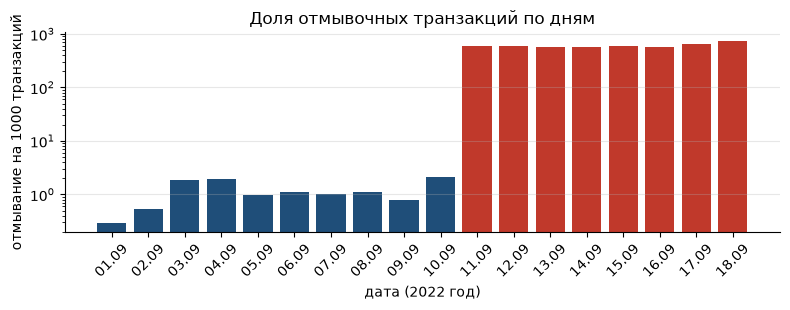

In [4]:
CUT = pd.Timestamp("2022-09-11")
days = pd.to_datetime(pd.Series(by_day.index))
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(days.dt.strftime("%d.%m"), by_day["на 1000"].values,
       color=[BLUE if d < CUT else RED for d in days])
ax.set_yscale("log")
ax.set_ylabel("отмывание на 1000 транзакций")
ax.set_xlabel("дата (2022 год)")
ax.set_title("Доля отмывочных транзакций по дням")
ax.tick_params(axis="x", rotation=45)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(FIG / "laundering_by_day.png")
plt.show()

Если оставить хвост, любой признак, связанный с датой, почти сразу выдаст метку. Поэтому все транзакции после 10.09.2022 исключены, а признаков, завязанных на дату, в модели нет совсем.

In [5]:
tail = tx[tx.ts >= CUT]
print(f"убрано после 10.09: {len(tail):,} транзакций, из них отмывание {int(tail.y.sum()):,}")
tx = tx[tx.ts < CUT].reset_index(drop=True)
print(f"осталось: {len(tx):,} транзакций, отмывание {int(tx.y.sum()):,} (1 на {len(tx) / tx.y.sum():.0f})")

убрано после 10.09: 1,108 транзакций, из них отмывание 655


осталось: 5,077,237 транзакций, отмывание 4,522 (1 на 1123)


### Перевод сумм в доллары

Суммы записаны в 15 валютах. Курс к доллару взят как медиана отношения «получено / отправлено» по переводам, где отправитель платил в своей валюте, а получатель получил доллары.

In [6]:
cross = tx[(tx.cur_paid != tx.cur_rec) & (tx.cur_rec == "US Dollar")]
rate = (cross.amt_rec / cross.amt_paid).groupby(cross.cur_paid).median()
rate["US Dollar"] = 1.0
tx["usd"] = tx.amt_paid * tx.cur_paid.map(rate)
assert tx.usd.notna().all()
rate.sort_values().round(4).rename("курс к USD").to_frame()

,курс к USD
cur_paid,
Yen,0.0095
Ruble,0.0129
Rupee,0.0136
Mexican Peso,0.0473
Yuan,0.1493
Brazil Real,0.1771
Saudi Riyal,0.2666
Shekel,0.2961
Australian Dollar,0.7078


### Счета → участники

In [7]:
acc["key"] = acc["Bank ID"].astype(int).astype(str) + "|" + acc["Account Number"]
ent_ids = acc["Entity ID"].unique()
N = len(ent_ids)
ent_pos = pd.Series(np.arange(N), index=ent_ids)
key2node = acc.set_index("key")["Entity ID"].map(ent_pos)

tx["src"] = (tx.from_bank.astype(int).astype(str) + "|" + tx.from_acc).map(key2node)
tx["dst"] = (tx.to_bank.astype(int).astype(str) + "|" + tx.to_acc).map(key2node)
assert tx[["src", "dst"]].notna().all().all()
tx["src"] = tx["src"].astype(np.int64)
tx["dst"] = tx["dst"].astype(np.int64)

names = acc.drop_duplicates("Entity ID").set_index("Entity ID")["Entity Name"].reindex(ent_ids).values
kind = pd.Series(names).str.replace(r"\s*#\d+$", "", regex=True).values
print(f"участников: {N:,}")
pd.Series(kind).value_counts().rename("участников").to_frame()

участников: 166,207


,участников
Corporation,55530
Sole Proprietorship,55369
Partnership,55170
Individual,134
Country,2
Direct,2


## 2. Метка участника

Участник считается причастным, если он отправил или получил хотя бы одну транзакцию с меткой отмывания.

In [8]:
lt = tx[tx.y == 1]
y = np.zeros(N, dtype=np.int64)
y[lt.src.values] = 1
y[lt.dst.values] = 1

senders, receivers = set(lt.src), set(lt.dst)
print(f"причастных: {y.sum():,} из {N:,} ({y.mean():.2%})")
print(f"только отправляли: {len(senders - receivers):,}, только получали: {len(receivers - senders):,}, "
      f"и то и другое: {len(senders & receivers):,}")
pd.crosstab(kind, y, margins=True).rename(columns={0: "нет", 1: "причастен", "All": "всего"})

причастных: 5,082 из 166,207 (3.06%)
только отправляли: 2,056, только получали: 2,208, и то и другое: 818


col_0,нет,причастен,всего
row_0,,,
Corporation,53603,1927,55530
Country,1,1,2
Direct,2,0,2
Individual,128,6,134
Partnership,53469,1701,55170
Sole Proprietorship,53922,1447,55369
All,161125,5082,166207


## 3. Признаки участников

Для каждого участника посчитаны:

- тип (корпорация, партнёрство, ИП, человек, прочее)
- сколько у него счетов и в скольких банках
- сколько переводов он отправил и получил, всего и по каждому способу оплаты
- сумму отправленного и полученного в долларах
- со сколькими разными участниками он переводил деньги
- сколько переводов он сделал сам себе
- сколько валют использовал, какая доля переводов шла в другой валюте и в другой банк

Считаются только переводы между разными участниками, кроме отдельного признака про переводы самому себе. Количества и суммы логарифмированы. Реинвестиции в данных бывают только переводами самому себе, поэтому их счётчики между участниками везде нулевые и убираются.

In [9]:
inter = tx[tx.src != tx.dst]
self_tx = tx[tx.src == tx.dst]
idx = pd.RangeIndex(N)
fmts = sorted(tx.fmt.unique())
feat = pd.DataFrame(index=idx)

per_ent = acc.groupby("Entity ID")
feat["n_accounts"] = per_ent.size().reindex(ent_ids).values
feat["n_banks"] = per_ent["Bank ID"].nunique().reindex(ent_ids).values

for side, col, other in (("out", "src", "dst"), ("in", "dst", "src")):
    g = inter.groupby(col)
    feat[f"{side}_count"] = g.size().reindex(idx, fill_value=0)
    feat[f"{side}_usd"] = g.usd.sum().reindex(idx, fill_value=0)
    feat[f"{side}_partners"] = g[other].nunique().reindex(idx, fill_value=0)
    ct = pd.crosstab(inter[col], inter.fmt).reindex(index=idx, columns=fmts, fill_value=0)
    for f in fmts:
        feat[f"{side}_{f.lower().replace(' ', '_')}"] = ct[f].values
    feat[f"{side}_cross_cur_share"] = (inter.cur_paid != inter.cur_rec).groupby(inter[col]).mean().reindex(idx, fill_value=0)
    feat[f"{side}_cross_bank_share"] = (inter.from_bank != inter.to_bank).groupby(inter[col]).mean().reindex(idx, fill_value=0)

feat["self_count"] = self_tx.groupby("src").size().reindex(idx, fill_value=0)
cur = pd.concat([pd.DataFrame({"node": tx.src, "cur": tx.cur_paid}),
                 pd.DataFrame({"node": tx.dst, "cur": tx.cur_rec})])
feat["n_currencies"] = cur.groupby("node").cur.nunique().reindex(idx, fill_value=0)

for k in ["Corporation", "Partnership", "Sole Proprietorship", "Individual"]:
    feat["kind_" + k.lower().replace(" ", "_")] = (kind == k).astype(int)
feat["kind_other"] = (~pd.Series(kind).isin(["Corporation", "Partnership", "Sole Proprietorship", "Individual"])).astype(int).values

share_cols = [c for c in feat.columns if c.endswith("_share") or c.startswith("kind_")]
log_cols = [c for c in feat.columns if c not in share_cols]
X_df = feat.copy()
X_df[log_cols] = np.log1p(X_df[log_cols].astype(float))
const = [c for c in X_df.columns if X_df[c].nunique() == 1]
X_df = X_df.drop(columns=const)
X = X_df.values.astype(np.float32)
print(f"убраны признаки с одним значением у всех: {const}")
print(f"признаков: {X.shape[1]}")
X_df.describe().T[["mean", "std", "min", "max"]].round(3)

убраны признаки с одним значением у всех: ['out_reinvestment', 'in_reinvestment']
признаков: 31


,mean,std,min,max
n_accounts,1.058,0.565,0.693,8.965
n_banks,1.055,0.554,0.693,7.078
out_count,2.074,1.608,0.000,12.036
out_usd,8.300,5.570,0.000,24.689
out_partners,1.003,0.816,0.000,9.554
out_ach,0.791,0.972,0.000,8.114
out_bitcoin,0.003,0.102,0.000,10.554
out_cash,0.573,0.964,0.000,10.441
out_cheque,1.479,1.351,0.000,11.318
out_credit_card,1.162,1.287,0.000,10.863


## 4. Граф участников

Узлы — участники. Ребро идёт от того, кто платил, к тому, кто получал. Несколько переводов между одной парой объединяются в одно ребро.

In [10]:
pairs = inter.groupby(["src", "dst"]).agg(n=("usd", "size"), usd=("usd", "sum")).reset_index()
edge_index = torch.tensor(pairs[["src", "dst"]].values.T, dtype=torch.long)
in_graph = np.zeros(N, dtype=bool)
in_graph[pairs.src.values] = True
in_graph[pairs.dst.values] = True
print(f"узлов: {N:,}, рёбер: {len(pairs):,}")
print(f"участников без переводов другим участникам: {(~in_graph).sum():,}, из них причастных: {y[~in_graph].sum()}")

узлов: 166,207, рёбер: 571,920
участников без переводов другим участникам: 3,310, из них причастных: 0


### Крупнейшие узлы

У нескольких участников тысячи счетов и десятки тысяч переводов. В GraphSAGE соседи усредняются, поэтому такой узел не перевешивает остальных одним объёмом.

In [11]:
deg = pd.Series(np.bincount(inter.src, minlength=N) + np.bincount(inter.dst, minlength=N))
top = deg.sort_values(ascending=False).head(5).index.values
pd.DataFrame({"участник": names[top], "счетов": feat.n_accounts.values[top],
              "переводов": deg[top].values, "причастен": y[top]})

,участник,счетов,переводов,причастен
0,Sole Proprietorship #41,6,169869,1
1,Partnership #2370,301,107922,1
2,Country #1,6677,56548,1
3,Corporation #34854,7820,46128,1
4,Partnership #38444,2511,32879,1


## 5. Разбиение на выборки

Одно стратифицированное разбиение 60/20/20 по участникам с фиксированным seed. Оно сохраняется в файл и одинаково для обеих моделей.

In [12]:
SPLIT = PROC / "split.npz"
if SPLIT.exists():
    s = np.load(SPLIT)
    idx_train, idx_val, idx_test = s["train"], s["val"], s["test"]
else:
    all_idx = np.arange(N)
    idx_train, idx_rest = train_test_split(all_idx, test_size=0.4, stratify=y, random_state=42)
    idx_val, idx_test = train_test_split(idx_rest, test_size=0.5, stratify=y[idx_rest], random_state=42)
    np.savez(SPLIT, train=idx_train, val=idx_val, test=idx_test)
for name, part in (("train", idx_train), ("val", idx_val), ("test", idx_test)):
    print(f"{name:5} {len(part):7,}  причастных {y[part].sum():5,} ({y[part].mean():.2%})")

train  99,724  причастных 3,049 (3.06%)
val    33,241  причастных 1,016 (3.06%)
test   33,242  причастных 1,017 (3.06%)


## 6. Проверка на утечку

Если какой-то один признак сам по себе почти идеально находит причастных, это подозрительно. Ниже average precision каждого признака на обучающей выборке. Для сравнения: случайный порядок даёт AP, равный доле причастных.

In [13]:
leak = {}
for j, c in enumerate(X_df.columns):
    v = X[idx_train, j]
    leak[c] = max(average_precision_score(y[idx_train], v), average_precision_score(y[idx_train], -v))
print(f"доля причастных в train: {y[idx_train].mean():.4f}")
pd.Series(leak).sort_values(ascending=False).head(10).round(4).rename("AP одного признака").to_frame()

доля причастных в train: 0.0306


,AP одного признака
in_partners,0.1264
n_accounts,0.1199
out_partners,0.1197
n_banks,0.1179
self_count,0.1144
in_count,0.1121
in_ach,0.1015
in_cheque,0.1013
out_ach,0.0999
out_count,0.0993


## 7. Метрики

Причастных около 3%, поэтому основная метрика — average precision (площадь под кривой точность-полнота). Дополнительно считаются ROC-AUC и F1. Порог для F1 подбирается на валидации и потом применяется к тесту.

In [14]:
def pick_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    return float(thr[np.nanargmax(f1[:-1])])


def evaluate(p_val, p_test):
    t = pick_threshold(y[idx_val], p_val)
    pred = (p_test >= t).astype(int)
    yt = y[idx_test]
    return {"ap": average_precision_score(yt, p_test), "roc_auc": roc_auc_score(yt, p_test),
            "f1": f1_score(yt, pred), "precision": precision_score(yt, pred, zero_division=0),
            "recall": recall_score(yt, pred), "threshold": t}


SEEDS = [0, 1, 2]

## 8. Модель без графа: градиентный бустинг

Те же признаки, но каждый участник рассматривается отдельно, соседи не учитываются. Результат каждого seed сохраняется в `results/`, при повторном запуске уже посчитанные seed не пересчитываются.

In [15]:
def run_baseline(seed):
    path = RES / f"baseline_seed{seed}.json"
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    clf = HistGradientBoostingClassifier(max_iter=500, learning_rate=0.05, class_weight="balanced",
                                         early_stopping=True, validation_fraction=0.1, random_state=seed)
    clf.fit(X[idx_train], y[idx_train])
    p_val = clf.predict_proba(X[idx_val])[:, 1]
    p_test = clf.predict_proba(X[idx_test])[:, 1]
    np.save(RES / f"baseline_seed{seed}_test_scores.npy", p_test)
    res = {"seed": seed, "iterations": int(clf.n_iter_), **evaluate(p_val, p_test)}
    path.write_text(json.dumps(res, ensure_ascii=False, indent=1), encoding="utf-8")
    return res


base_runs = [run_baseline(s) for s in SEEDS]
pd.DataFrame(base_runs).round(4)

,seed,iterations,ap,roc_auc,f1,precision,recall,threshold
0,0,96,0.2510,0.8429,0.2846,0.2880,0.2812,0.8052
1,1,111,0.2548,0.8426,0.2857,0.2761,0.2960,0.7990
2,2,132,0.2586,0.8425,0.2865,0.2629,0.3147,0.7894


## 9. GraphSAGE на графе участников

Сначала признаки участника переводятся в скрытое представление. Дальше два слоя, и на каждом участник получает:

- усреднённые представления тех, кто ему платил
- отдельно усреднённые представления тех, кому платил он
- своё собственное представление

После двух слоёв модель видит соседей своих соседей, то есть цепочки длиной до двух переводов. Направление денег важно, поэтому входящие и исходящие связи обрабатываются разными весами.

Классы несбалансированы, поэтому в функции потерь причастные взвешены в отношении «непричастных к причастным» на обучающей выборке. Обучение останавливается, если AP на валидации не растёт 60 эпох.

Сохранение по ходу обучения:

- метрики каждой эпохи пишутся в `results/gnn_seed*_epochs.csv`
- веса лучшей эпохи — в `results/gnn_seed*_best.pt`
- состояние после каждой эпохи — в `results/gnn_seed*_last.pt`

Если обучение прервётся, при повторном запуске оно продолжится с последней сохранённой эпохи.

In [16]:
class DirSAGE(torch.nn.Module):
    def __init__(self, d_in, d_hidden=64, layers=2, dropout=0.3):
        super().__init__()
        self.inp = torch.nn.Linear(d_in, d_hidden)
        self.conv_in = torch.nn.ModuleList([SAGEConv(d_hidden, d_hidden, aggr="mean") for _ in range(layers)])
        self.conv_out = torch.nn.ModuleList([SAGEConv(d_hidden, d_hidden, aggr="mean") for _ in range(layers)])
        self.norms = torch.nn.ModuleList([torch.nn.BatchNorm1d(d_hidden) for _ in range(layers)])
        self.head = torch.nn.Linear(d_hidden, 1)
        self.dropout = dropout

    def forward(self, x, ei, ei_rev):
        h = Fn.relu(self.inp(x))
        for c_in, c_out, bn in zip(self.conv_in, self.conv_out, self.norms):
            z = c_in(h, ei) + c_out(h, ei_rev)
            z = Fn.relu(bn(z))
            h = h + Fn.dropout(z, p=self.dropout, training=self.training)
        return self.head(h).squeeze(-1)


mu, sd = X[idx_train].mean(0), X[idx_train].std(0) + 1e-6
x_t = torch.tensor((X - mu) / sd, dtype=torch.float32, device=DEVICE)
ei = edge_index.to(DEVICE)
ei_rev = ei.flip(0)
y_t = torch.tensor(y, dtype=torch.float32, device=DEVICE)
tr_t = torch.tensor(idx_train, device=DEVICE)
va_t = torch.tensor(idx_val, device=DEVICE)
te_t = torch.tensor(idx_test, device=DEVICE)
pos_weight = torch.tensor((y[idx_train] == 0).sum() / y[idx_train].sum(), device=DEVICE)

MAX_EPOCHS, PATIENCE = 500, 60
print(f"pos_weight = {pos_weight.item():.1f}")

pos_weight = 31.7


In [17]:
def predict(model, e, e_rev):
    model.eval()
    with torch.no_grad():
        return torch.sigmoid(model(x_t, e, e_rev)).cpu().numpy()


def run_net(seed, prefix="gnn", e=ei, e_rev=ei_rev, layers=2):
    out_json = RES / f"{prefix}_seed{seed}.json"
    if out_json.exists():
        return json.loads(out_json.read_text(encoding="utf-8"))
    epochs_csv = RES / f"{prefix}_seed{seed}_epochs.csv"
    best_pt, last_pt = RES / f"{prefix}_seed{seed}_best.pt", RES / f"{prefix}_seed{seed}_last.pt"

    torch.manual_seed(seed)
    model = DirSAGE(X.shape[1], layers=layers).to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=5e-3, weight_decay=5e-4)
    start, best, wait, hist = 0, -1.0, 0, []
    if last_pt.exists() and epochs_csv.exists():
        st = torch.load(last_pt, map_location=DEVICE)
        model.load_state_dict(st["model"])
        opt.load_state_dict(st["opt"])
        start, best, wait = st["epoch"] + 1, st["best"], st["wait"]
        hist = pd.read_csv(epochs_csv).to_dict("records")
        print(f"{prefix} seed {seed}: продолжение с эпохи {start}")

    for epoch in range(start, MAX_EPOCHS):
        model.train()
        opt.zero_grad()
        logits = model(x_t, e, e_rev)
        loss = Fn.binary_cross_entropy_with_logits(logits[tr_t], y_t[tr_t], pos_weight=pos_weight)
        loss.backward()
        opt.step()

        p = predict(model, e, e_rev)
        val_ap = average_precision_score(y[idx_val], p[idx_val])
        hist.append({"epoch": epoch, "loss": loss.item(), "val_ap": val_ap})
        pd.DataFrame(hist).to_csv(epochs_csv, index=False)
        if val_ap > best:
            best, wait = val_ap, 0
            torch.save(model.state_dict(), best_pt)
        else:
            wait += 1
        torch.save({"model": model.state_dict(), "opt": opt.state_dict(), "epoch": epoch,
                    "best": best, "wait": wait}, last_pt)
        if epoch % 50 == 0:
            print(f"{prefix} seed {seed} эпоха {epoch:3d}: loss {loss.item():.4f}, AP на валидации {val_ap:.4f}")
        if wait >= PATIENCE:
            break

    model.load_state_dict(torch.load(best_pt, map_location=DEVICE))
    p = predict(model, e, e_rev)
    np.save(RES / f"{prefix}_seed{seed}_test_scores.npy", p[idx_test])
    np.save(RES / f"{prefix}_seed{seed}_all_scores.npy", p)
    hdf = pd.DataFrame(hist)
    best_epoch = int(hdf.loc[hdf.val_ap.idxmax(), "epoch"])
    res = {"seed": seed, "best_epoch": best_epoch, "epochs": len(hist), **evaluate(p[idx_val], p[idx_test])}
    out_json.write_text(json.dumps(res, ensure_ascii=False, indent=1), encoding="utf-8")
    print(f"{prefix} seed {seed}: лучшая эпоха {best_epoch}, AP на тесте {res['ap']:.4f}")
    return res


gnn_runs = [run_net(s, "gnn") for s in SEEDS]
pd.DataFrame(gnn_runs).round(4)

gnn seed 0 эпоха   0: loss 1.5297, AP на валидации 0.0812


gnn seed 0 эпоха  50: loss 0.7948, AP на валидации 0.2746


gnn seed 0 эпоха 100: loss 0.6122, AP на валидации 0.3218


gnn seed 0 эпоха 150: loss 0.4725, AP на валидации 0.3231


gnn seed 0: лучшая эпоха 128, AP на тесте 0.3459
gnn seed 1 эпоха   0: loss 1.8458, AP на валидации 0.0722


gnn seed 1 эпоха  50: loss 0.8075, AP на валидации 0.2702


... (4 outputs left out)

gnn seed 2 эпоха 100: loss 0.5715, AP на валидации 0.3110


gnn seed 2 эпоха 150: loss 0.4949, AP на валидации 0.3119


gnn seed 2: лучшая эпоха 138, AP на тесте 0.3369


,seed,best_epoch,epochs,ap,roc_auc,f1,precision,recall,threshold
0,0,128,189,0.3459,0.8619,0.3727,0.4635,0.3117,0.9121
1,1,119,180,0.3335,0.8604,0.3562,0.3947,0.3245,0.8753
2,2,138,199,0.3369,0.8606,0.3511,0.3970,0.3147,0.9258


## 10. Та же нейросеть без графа

Бустинг и GraphSAGE отличаются не только графом: это разные модели с разным обучением. Чтобы отделить вклад графа, та же сеть обучается с тем же циклом обучения, но с пустым списком рёбер. Тогда каждый участник видит только свои признаки.

In [18]:
no_edges = torch.empty((2, 0), dtype=torch.long, device=DEVICE)
mlp_runs = [run_net(s, "mlp", no_edges, no_edges) for s in SEEDS]
pd.DataFrame(mlp_runs).round(4)

mlp seed 0 эпоха   0: loss 1.5141, AP на валидации 0.1147


mlp seed 0 эпоха  50: loss 0.9344, AP на валидации 0.2198


mlp seed 0 эпоха 100: loss 0.8246, AP на валидации 0.2352


mlp seed 0 эпоха 150: loss 0.7626, AP на валидации 0.2328


mlp seed 0 эпоха 200: loss 0.6885, AP на валидации 0.2289


mlp seed 0: лучшая эпоха 155, AP на тесте 0.2448
mlp seed 1 эпоха   0: loss 1.9913, AP на валидации 0.1138


... (5 outputs left out)

mlp seed 2 эпоха  50: loss 0.9208, AP на валидации 0.2273


mlp seed 2 эпоха 100: loss 0.8123, AP на валидации 0.2334


mlp seed 2: лучшая эпоха 82, AP на тесте 0.2437


,seed,best_epoch,epochs,ap,roc_auc,f1,precision,recall,threshold
0,0,155,216,0.2448,0.8161,0.2748,0.2643,0.2861,0.8603
1,1,176,237,0.2395,0.8180,0.2706,0.2748,0.2665,0.8508
2,2,82,143,0.2437,0.8217,0.2701,0.3310,0.2281,0.8527


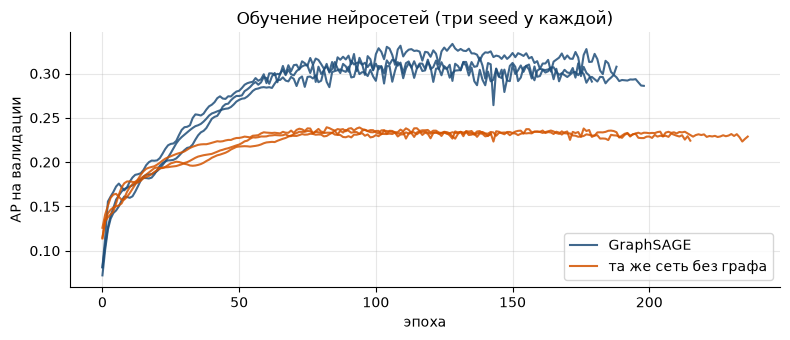

In [19]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for prefix, color, title in (("gnn", BLUE, "GraphSAGE"), ("mlp", ORANGE, "та же сеть без графа")):
    for s in SEEDS:
        h = pd.read_csv(RES / f"{prefix}_seed{s}_epochs.csv")
        ax.plot(h.epoch, h.val_ap, color=color, alpha=0.85, label=title if s == 0 else None)
ax.set_xlabel("эпоха")
ax.set_ylabel("AP на валидации")
ax.set_title("Обучение нейросетей (три seed у каждой)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG / "training_curves.png")
plt.show()

## 11. Сравнение

In [20]:
rows = []
for title, runs in (("Градиентный бустинг, без графа", base_runs), ("Та же нейросеть, без графа", mlp_runs),
                    ("GraphSAGE, граф участников", gnn_runs)):
    df = pd.DataFrame(runs)
    rows.append({"модель": title, **{m: f"{df[m].mean():.3f} ± {df[m].std():.3f}"
                                     for m in ["ap", "roc_auc", "f1", "precision", "recall"]}})
summary = pd.DataFrame(rows).set_index("модель")
summary.to_csv(RES / "summary.csv", encoding="utf-8")
print(f"доля причастных в тесте (AP случайной модели): {y[idx_test].mean():.4f}")
summary

доля причастных в тесте (AP случайной модели): 0.0306


,ap,roc_auc,f1,precision,recall
модель,,,,,
"Градиентный бустинг, без графа",0.255 ± 0.004,0.843 ± 0.000,0.286 ± 0.001,0.276 ± 0.013,0.297 ± 0.017
"Та же нейросеть, без графа",0.243 ± 0.003,0.819 ± 0.003,0.272 ± 0.003,0.290 ± 0.036,0.260 ± 0.030
"GraphSAGE, граф участников",0.339 ± 0.006,0.861 ± 0.001,0.360 ± 0.011,0.418 ± 0.039,0.317 ± 0.007


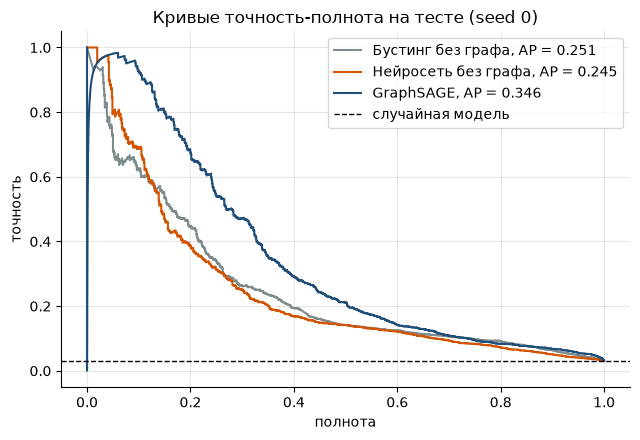

In [21]:
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for title, prefix, color in (("Бустинг без графа", "baseline", GRAY), ("Нейросеть без графа", "mlp", ORANGE),
                             ("GraphSAGE", "gnn", BLUE)):
    p = np.load(RES / f"{prefix}_seed0_test_scores.npy")
    prec, rec, _ = precision_recall_curve(y[idx_test], p)
    ax.plot(rec, prec, color=color, label=f"{title}, AP = {average_precision_score(y[idx_test], p):.3f}")
ax.axhline(y[idx_test].mean(), color="black", ls="--", lw=1, label="случайная модель")
ax.set_xlabel("полнота")
ax.set_ylabel("точность")
ax.set_title("Кривые точность-полнота на тесте (seed 0)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
fig.savefig(FIG / "pr_curve.png")
plt.show()

## 12. Кого модель считает самыми подозрительными

Десять участников тестовой выборки с наибольшей оценкой GraphSAGE (seed 0).

In [22]:
p_all = np.load(RES / "gnn_seed0_all_scores.npy")
top = idx_test[np.argsort(-p_all[idx_test])[:10]]
pd.DataFrame({"участник": names[top], "оценка": p_all[top].round(3), "счетов": feat.n_accounts.values[top],
              "отправил": feat.out_count.values[top], "получил": feat.in_count.values[top],
              "контрагентов": (feat.out_partners + feat.in_partners).values[top], "причастен": y[top]})

,участник,оценка,счетов,отправил,получил,контрагентов,причастен
0,Partnership #13440,1.0,1,2,15,5,0
1,Corporation #46410,1.0,2,23,1,4,1
2,Corporation #40757,1.0,1,61,25,7,1
3,Sole Proprietorship #24408,1.0,3,30,23,4,1
4,Partnership #39872,1.0,1,7,45,11,1
5,Partnership #45448,1.0,1,9,39,26,1
6,Corporation #23891,1.0,1,1,44,3,1
7,Sole Proprietorship #31232,1.0,1,56,42,19,1
8,Partnership #26892,1.0,1,1,16,3,1
9,Partnership #45967,1.0,1,14,18,5,1


## 13. Сколько шагов по связям нужно модели

Число слоёв GraphSAGE показывает, на сколько переводов от участника модель может «дотянуться». Сравниваются один, два и три слоя, остальное без изменений.

In [23]:
depth_runs = {1: [run_net(s, "gnn_l1", layers=1) for s in SEEDS], 2: gnn_runs,
              3: [run_net(s, "gnn_l3", layers=3) for s in SEEDS]}
depth = pd.DataFrame([{"слоёв": k, **{m: f"{pd.DataFrame(v)[m].mean():.3f} ± {pd.DataFrame(v)[m].std():.3f}"
                                     for m in ["ap", "roc_auc", "f1"]}}
                      for k, v in depth_runs.items()]).set_index("слоёв")
depth.to_csv(RES / "depth.csv", encoding="utf-8")
depth

gnn_l1 seed 0 эпоха   0: loss 1.4428, AP на валидации 0.0799


gnn_l1 seed 0 эпоха  50: loss 0.8132, AP на валидации 0.2520


gnn_l1 seed 0 эпоха 100: loss 0.6544, AP на валидации 0.2860


gnn_l1 seed 0 эпоха 150: loss 0.5544, AP на валидации 0.3046


gnn_l1 seed 0 эпоха 200: loss 0.4902, AP на валидации 0.2915


gnn_l1 seed 0 эпоха 250: loss 0.4397, AP на валидации 0.2988


... (21 outputs left out)

gnn_l3 seed 2 эпоха 100: loss 0.5542, AP на валидации 0.3081


gnn_l3 seed 2 эпоха 150: loss 0.4295, AP на валидации 0.3262


gnn_l3 seed 2: лучшая эпоха 134, AP на тесте 0.3547


,ap,roc_auc,f1
слоёв,,,
1,0.315 ± 0.003,0.857 ± 0.005,0.336 ± 0.002
2,0.339 ± 0.006,0.861 ± 0.001,0.360 ± 0.011
3,0.350 ± 0.008,0.862 ± 0.005,0.361 ± 0.014


## 14. Какие схемы отмывания находит модель

В файле `HI-Small_Patterns.txt` перечислены попытки отмывания восьми типов. Для каждого типа взяты причастные участники тестовой выборки, которые участвовали в таких попытках, и посчитано, какую долю из них нашла каждая модель при пороге, подобранном на валидации. Отдельно посчитаны причастные, которые ни в одну схему из файла не входят. Доли усреднены по трём seed.

In [24]:
rows = []
cur_type = None
for line in (DATA / "HI-Small_Patterns.txt").read_text(encoding="utf-8").splitlines():
    if line.startswith("BEGIN LAUNDERING ATTEMPT"):
        cur_type = line.split(" - ", 1)[1].split(":")[0].strip()
    elif line.startswith("END LAUNDERING ATTEMPT"):
        cur_type = None
    elif cur_type and line.strip():
        f = line.split(",")
        rows.append((cur_type, f[0], f[1], f[2], f[3], f[4]))
pat = pd.DataFrame(rows, columns=["type", "ts", "from_bank", "from_acc", "to_bank", "to_acc"])
pat["ts"] = pd.to_datetime(pat.ts, format="%Y/%m/%d %H:%M")
print(f"транзакций в схемах: {len(pat):,}, из них до 11.09: {(pat.ts < CUT).sum():,}")
pat = pat[pat.ts < CUT].copy()
pat["src"] = (pat.from_bank.astype(int).astype(str) + "|" + pat.from_acc).map(key2node)
pat["dst"] = (pat.to_bank.astype(int).astype(str) + "|" + pat.to_acc).map(key2node)
assert pat[["src", "dst"]].notna().all().all()
node_type = pd.concat([pat[["type", "src"]].set_axis(["type", "node"], axis=1),
                       pat[["type", "dst"]].set_axis(["type", "node"], axis=1)]).drop_duplicates()
node_type["node"] = node_type["node"].astype(np.int64)

test_mask = np.zeros(N, dtype=bool)
test_mask[idx_test] = True
pos_test = test_mask & (y == 1)
in_any = np.zeros(N, dtype=bool)
in_any[node_type.node.values] = True
print(f"участников в схемах: {in_any.sum():,}, из них причастных по метке: {y[in_any].sum():,}")

groups = {t: np.unique(node_type.node[node_type.type == t].values) for t in sorted(node_type.type.unique())}
groups = {t: v[pos_test[v]] for t, v in groups.items()}
groups["вне схем"] = np.where(pos_test & ~in_any)[0]


def found_mask(prefix, seed):
    r = json.loads((RES / f"{prefix}_seed{seed}.json").read_text(encoding="utf-8"))
    p = np.full(N, -1.0)
    p[idx_test] = np.load(RES / f"{prefix}_seed{seed}_test_scores.npy")
    return p >= r["threshold"]


MODELS = (("бустинг без графа", "baseline", GRAY), ("сеть без графа", "mlp", ORANGE), ("GraphSAGE", "gnn", BLUE))
tab = pd.DataFrame({"причастных в тесте": {t: len(v) for t, v in groups.items()}})
for title, prefix, _ in MODELS:
    masks = [found_mask(prefix, s) for s in SEEDS]
    tab[title] = {t: np.mean([m[v].mean() for m in masks]) for t, v in groups.items()}
tab = tab.sort_values("причастных в тесте", ascending=False)
tab.to_csv(RES / "pattern_recall.csv", encoding="utf-8")
tab.round(3)

транзакций в схемах: 3,209, из них до 11.09: 2,554
участников в схемах: 2,427, из них причастных по метке: 2,427


,причастных в тесте,бустинг без графа,сеть без графа,GraphSAGE
вне схем,521,0.155,0.125,0.118
STACK,123,0.496,0.472,0.450
GATHER-SCATTER,98,0.405,0.364,0.694
BIPARTITE,83,0.434,0.394,0.361
FAN-OUT,71,0.362,0.329,0.662
SCATTER-GATHER,61,0.585,0.574,0.798
FAN-IN,49,0.510,0.429,0.429
CYCLE,48,0.653,0.556,0.542
RANDOM,26,0.628,0.526,0.564


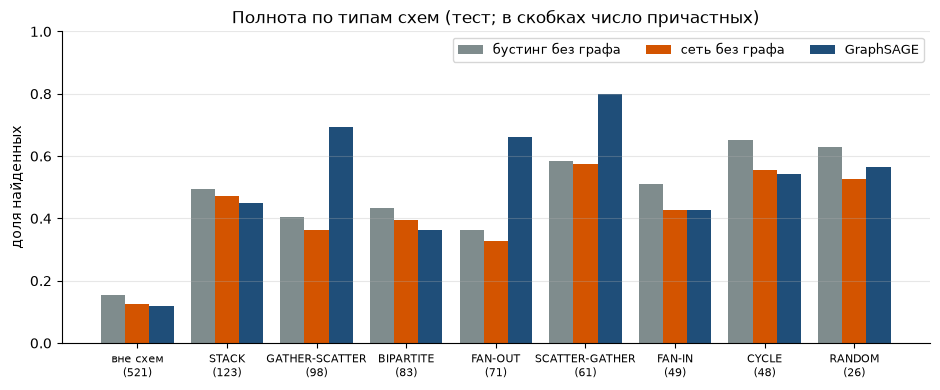

In [25]:
fig, ax = plt.subplots(figsize=(9.5, 4))
xpos = np.arange(len(tab))
w = 0.27
for i, (title, _, color) in enumerate(MODELS):
    ax.bar(xpos + (i - 1) * w, tab[title].values, w, color=color, label=title)
ax.set_xticks(xpos, [f"{t}\n({n})" for t, n in zip(tab.index, tab["причастных в тесте"])], fontsize=8)
ax.set_ylabel("доля найденных")
ax.set_ylim(0, 1)
ax.set_title("Полнота по типам схем (тест; в скобках число причастных)")
ax.legend(ncol=3, loc="upper right", fontsize=9)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
fig.savefig(FIG / "pattern_recall.png")
plt.show()

## 15. Пример: участник, которого нашёл только GraphSAGE

Выбран причастный участник из теста, которого GraphSAGE отметил, а обе модели без графа пропустили (seed 0). Ниже нарисованы его ближайшие связи. Красным отмечены причастные, серым остальные, стрелка показывает направление денег, толщина — число переводов. Метки соседей модель не видела, только их признаки и связи.

In [26]:
r0 = {pfx: json.loads((RES / f"{pfx}_seed0.json").read_text(encoding="utf-8")) for pfx in ("baseline", "mlp", "gnn")}
p_gnn = np.load(RES / "gnn_seed0_all_scores.npy")
p_mlp = np.load(RES / "mlp_seed0_all_scores.npy")
p_base = np.full(N, np.nan)
p_base[idx_test] = np.load(RES / "baseline_seed0_test_scores.npy")
nbr = pd.concat([pairs[["src", "dst"]], pairs[["dst", "src"]].set_axis(["src", "dst"], axis=1)]).drop_duplicates()
n_nbr = nbr.groupby("src").size().reindex(idx, fill_value=0).values

only_gnn = [v for v in idx_test if y[v] == 1 and p_gnn[v] >= r0["gnn"]["threshold"]
            and p_mlp[v] < r0["mlp"]["threshold"] and p_base[v] < r0["baseline"]["threshold"]]
print(f"причастных в тесте, которых нашёл только GraphSAGE: {len(only_gnn)} из {pos_test.sum()}")


def pick(lo, hi):
    return sorted([v for v in only_gnn if lo <= n_nbr[v] <= hi], key=lambda v: (-int(in_any[v]), -p_gnn[v]))


cand = pick(4, 9) or pick(2, 15) or pick(1, 10**9)
v0 = cand[0]
types_v0 = sorted(node_type.type[node_type.node == v0].unique())
print(f"участник: {names[v0]}, контрагентов: {n_nbr[v0]}, схемы: {', '.join(types_v0) if types_v0 else 'нет'}")
print(f"GraphSAGE {p_gnn[v0]:.3f} (порог {r0['gnn']['threshold']:.3f}), "
      f"сеть без графа {p_mlp[v0]:.3f} (порог {r0['mlp']['threshold']:.3f}), "
      f"бустинг {p_base[v0]:.3f} (порог {r0['baseline']['threshold']:.3f})")

sub_nodes = [v0] + sorted(nbr.dst[nbr.src == v0].tolist())
rows = []
for u in sub_nodes[1:]:
    e_out = pairs[(pairs.src == v0) & (pairs.dst == u)]
    e_in = pairs[(pairs.src == u) & (pairs.dst == v0)]
    rows.append({"контрагент": names[u], "причастен": y[u], "он → контрагент": int(e_out.n.sum()),
                 "контрагент → он": int(e_in.n.sum()), "сумма, USD": round(float(e_out.usd.sum() + e_in.usd.sum()))})
pd.DataFrame(rows)

причастных в тесте, которых нашёл только GraphSAGE: 86 из 1017
участник: Corporation #46410, контрагентов: 4, схемы: FAN-OUT
GraphSAGE 1.000 (порог 0.912), сеть без графа 0.766 (порог 0.860), бустинг 0.757 (порог 0.805)


,контрагент,причастен,он → контрагент,контрагент → он,"сумма, USD"
0,Corporation #26327,0,2,0,6084
1,Sole Proprietorship #2069,1,0,1,15067
2,Corporation #23262,0,1,0,684
3,Corporation #53396,0,20,0,194


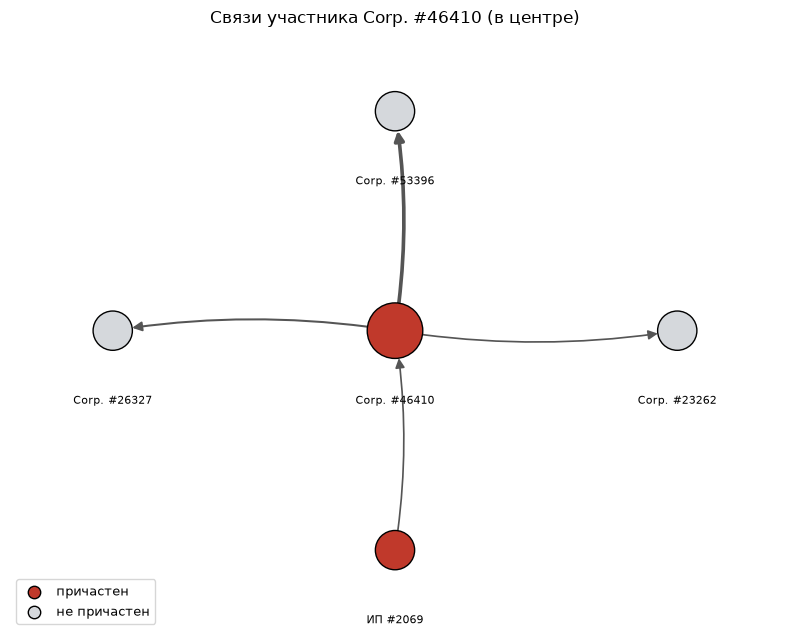

In [27]:
short = lambda s: s.replace("Sole Proprietorship", "ИП").replace("Corporation", "Corp.").replace("Partnership", "Partn.")
G = nx.DiGraph()
G.add_nodes_from(sub_nodes)
for row in pairs[pairs.src.isin(sub_nodes) & pairs.dst.isin(sub_nodes)].itertuples():
    G.add_edge(row.src, row.dst, n=row.n)
pos = nx.shell_layout(G, nlist=[[v0], sub_nodes[1:]])
sizes = [1600 if u == v0 else 800 for u in G.nodes]
fig, ax = plt.subplots(figsize=(8, 6.5))
nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#555555", arrows=True, arrowsize=14, node_size=sizes,
                       width=[0.8 + 0.6 * np.log1p(G.edges[e]["n"]) for e in G.edges], connectionstyle="arc3,rad=0.08")
nx.draw_networkx_nodes(G, pos, ax=ax, node_size=sizes, edgecolors="black",
                       node_color=[RED if y[u] else "#d5d8dc" for u in G.nodes])
nx.draw_networkx_labels(G, {u: (px, py - 0.16) for u, (px, py) in pos.items()},
                        {u: short(names[u]) for u in G.nodes}, ax=ax, font_size=8)
ax.scatter([], [], s=80, color=RED, edgecolors="black", label="причастен")
ax.scatter([], [], s=80, color="#d5d8dc", edgecolors="black", label="не причастен")
ax.legend(loc="lower left", fontsize=9)
ax.set_title(f"Связи участника {short(names[v0])} (в центре)")
ax.margins(0.12)
ax.axis("off")
plt.tight_layout()
fig.savefig(FIG / "example_subgraph.png")
plt.show()

## Выводы

- Причастных к отмыванию 5 082 из 166 207 участников (3,06%), поэтому случайная модель даёт AP около 0,031.
- Градиентный бустинг без графа: AP 0,255 ± 0,004, ROC-AUC 0,843, F1 0,286 ± 0,001.
- Та же нейросеть, что и GraphSAGE, но без рёбер: AP 0,243 ± 0,003, ROC-AUC 0,819, F1 0,272 ± 0,003.
- GraphSAGE на графе участников: AP 0,339 ± 0,006, ROC-AUC 0,861, F1 0,360 ± 0,011.
- Разброс ± посчитан по трём seed модели на одном и том же разбиении.
- Нейросеть без рёбер работает на уровне бустинга, а с рёбрами AP вырастает примерно на 0,1. Значит, прирост связан с информацией о том, с кем участник обменивался деньгами.
- Уже один слой, то есть только прямые контрагенты, даёт AP 0,315. Два слоя дают 0,339, три слоя 0,350.
- Сильнее всего граф помогает на схемах FAN-OUT, GATHER-SCATTER и SCATTER-GATHER: доля найденных у GraphSAGE 0,66, 0,69 и 0,80 против 0,36, 0,40 и 0,58 у бустинга. В этих схемах есть счёт, связанный сразу со многими участниками схемы. На цепочках (CYCLE, STACK, BIPARTITE, RANDOM) и на FAN-IN при выбранных порогах GraphSAGE находит не больше бустинга.
- 521 из 1 017 причастных в тесте не входят ни в одну схему из файла, и их все три модели находят плохо (от 12% до 16%).
- Ни один признак сам по себе не даёт AP выше 0,13, так что модели не опираются на какой-то один признак, который выдаёт метку.
- Все пять самых крупных участников по числу переводов помечены как причастные. При десятках тысяч переводов у них почти наверняка найдётся хотя бы одна отмывочная транзакция, поэтому для таких участников метка мало что значит.

Ограничения:

- данные синтетические
- причастным считается и тот, кто только получал отмывочные деньги (2 208 участников из 5 082)
- по определению метки оба конца отмывочного перевода причастны, поэтому у каждого причастного есть хотя бы один причастный сосед, и часть выигрыша от графа заложена в саму метку
- разбиение по участникам, а не по времени: граф строится по всем переводам периода, модель видит связи и тестовых участников, но не их метки
- доли найденных по схемам сравниваются при порогах, подобранных для каждой модели отдельно, а у GraphSAGE порог строже (точность 0,42 против 0,28 у бустинга)
- результат не сравним с цифрами из статьи IBM, там классифицировали транзакции, а не участников